# Are train crashes more common and dangerous in Germany than in the rest of Europe?

This project seeks to investigate if train crashes are worse in Germany than in other European countries.

To understand this we will first ask compare the number of incidents across countries, as well as the type of incident

Then, we will compare the average number of incidents per kilometre of track. Larger countries are likely to have more major incidents due to their size. Investigating the number of incidents per kilometre of track could suggest whether there are deeper issues with that nation's rail network, for example with track quality.

Finally, we will compare the average number of incidents per capita. Countries with larger populations are likely to have higher usage of their rail networks. Therefore, even if the number of train derailemnts were equal across all countries, counties with higher passenger counts would show more casualties. For this reason, incidents per capita will be a rough indicator for the level of danger that a rail network poses by passenger volume, and may suggest if the network is overcrowded.

Data for this project is taken from the European Union Agency for Railways's dataset "Common Safety Indicators (CSIs)". Data spans from 2006-2024 and contains information on the types of incidents, numbers of casualties, economic impacts, the proliferation of safety measures, among other factors. We will primarily be using data from 2024. This dataset can be found here: https://www.era.europa.eu/domains/accident-incident/common-safety-indicators-csis

## Data extraction and cleaning

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# extracting the total number of incidents
incidents = pd.read_excel("csidata_2006-2024.xlsx", sheet_name="Table 0")
incidents.head(10)

,Unnamed: 0,Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,...,Unnamed: 23,Unnamed: 24,Unnamed: 25,Unnamed: 26,Unnamed: 27,Unnamed: 28,Unnamed: 29,Unnamed: 30,Unnamed: 31,Unnamed: 32
0,NaN,Code,CSI,Year,AT,BE,BG,CH,CT,CZ,...,LV,NL,NO,PL,PT,RO,SE,SI,SK,UK
1,NaN,N00,Total number of significant accidents,2006,106,187,84,NaN,NaN,233,...,63,28,16,928,89,419,51,70,199,85
2,NaN,NaN,NaN,2007,104,217,56,NaN,0,115,...,51,33,12,976,93,370,56,61,222,110
3,NaN,NaN,NaN,2008,97,220,65,NaN,2,133,...,61,26,15,889,73,411,46,65,217,104
4,NaN,NaN,NaN,2009,88,146,48,58,1,113,...,40,22,17,523,43,304,46,19,236,104
5,NaN,NaN,NaN,2010,79,40,39,51,1,125,...,41,24,20,449,42,271,69,21,85,62
6,NaN,NaN,NaN,2011,84,51,74,44,2,99,...,35,29,36,488,27,217,54,11,84,78
7,NaN,NaN,NaN,2012,87,36,48,43,2,97,...,25,30,19,379,36,215,47,14,96,75
8,NaN,NaN,NaN,2013,73,32,33,43,1,91,...,26,36,30,328,48,180,43,13,94,84
9,NaN,NaN,NaN,2014,61,47,58,55,0,105,...,22,20,28,313,50,185,53,15,113,54


In [2]:
# rename columns
incidents = incidents.rename(columns=incidents.loc[0])

# remove blank and duplicate rows
incidents.drop([0], inplace=True)

# reset row numbers
incidents = incidents.reset_index()

# remove first three empty columns
incidents = incidents.iloc[:, 3:]

# show incidents table
incidents.head(10)

,CSI,Year,AT,BE,BG,CH,CT,CZ,DE,DK,...,LV,NL,NO,PL,PT,RO,SE,SI,SK,UK
0,Total number of significant accidents,2006,106,187,84,NaN,NaN,233,983,32,...,63,28,16,928,89,419,51,70,199,85
1,NaN,2007,104,217,56,NaN,0,115,320,13,...,51,33,12,976,93,370,56,61,222,110
2,NaN,2008,97,220,65,NaN,2,133,329,15,...,61,26,15,889,73,411,46,65,217,104
3,NaN,2009,88,146,48,58,1,113,310,21,...,40,22,17,523,43,304,46,19,236,104
4,NaN,2010,79,40,39,51,1,125,297,16,...,41,24,20,449,42,271,69,21,85,62
5,NaN,2011,84,51,74,44,2,99,285,16,...,35,29,36,488,27,217,54,11,84,78
6,NaN,2012,87,36,48,43,2,97,289,21,...,25,30,19,379,36,215,47,14,96,75
7,NaN,2013,73,32,33,43,1,91,301,11,...,26,36,30,328,48,180,43,13,94,84
8,NaN,2014,61,47,58,55,0,105,333,15,...,22,20,28,313,50,185,53,15,113,54
9,NaN,2015,77,21,48,33,1,94,306,13,...,25,31,19,307,23,141,40,14,87,40


In [3]:
# updating NaN values from CSI column
CSI = incidents["CSI"][0]
for index, row in incidents.iterrows():
    if row["Year"] != 2006:
        incidents["CSI"][index] = CSI
    else:
        CSI = row["CSI"]

C:\Users\amyed\AppData\Local\Temp\ipykernel_71136\864196433.py:5: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  incidents["CSI"][index] = CSI


In [4]:
# select 2024 data only
incidents2024 = incidents[incidents["Year"] == 2024]

# reindex this table
incidents2024 = incidents2024.reset_index()
incidents2024 = incidents2024.iloc[:, 1:]

# remove UK from the dataset, this this was not in the EU in 2024
incidents2024 = incidents2024.drop(columns=["UK"])

#remove the Year column, since all data points are in 2024 in this table
incidents2024 = incidents2024.drop(columns=["Year"])

incidents2024.head(10)

,CSI,AT,BE,BG,CH,CT,CZ,DE,DK,EE,...,LU,LV,NL,NO,PL,PT,RO,SE,SI,SK
0,Total number of significant accidents,38,30,41,53,0,72,366,14,11,...,2,14,22,28,220,30,90,55,4,61
1,Collisions of trains,3,1,3,4,0,12,42,5,2,...,1,0,1,16,3,5,0,5,0,1
2,Collisions of train with rail vehicle,2,0,1,0,0,5,5,2,0,...,0,0,0,0,1,0,0,1,0,0
3,Collisions of train with obstacle within the c...,1,1,2,4,0,7,37,3,2,...,1,0,1,16,2,5,0,4,0,1
4,Derailments of trains,6,0,3,3,0,0,6,0,0,...,0,0,0,3,6,0,1,4,2,2
5,Level-crossing accidents,14,15,9,2,0,32,57,1,5,...,0,4,17,4,52,5,17,11,1,15
6,Level crossing accidents on passive LCs,6,0,2,0,0,7,18,0,3,...,0,1,2,4,29,3,12,1,0,4
7,Level crossing accidents on manual LCs,0,0,0,0,0,0,0,0,0,...,0,0,0,0,2,0,0,0,0,1
8,Level crossing accidents on LCs automatic with...,7,1,5,0,0,17,6,0,2,...,0,2,0,0,12,1,4,3,0,5
9,Level crossing accidents on LCs automatic with...,1,14,2,2,0,7,33,1,0,...,0,1,15,0,9,1,1,6,1,1


We have now fully prepared this table for analysis. Let's prepare the table for track length next.

In [5]:
# extracting the total number of track km
trackkm = pd.read_excel("csidata_2006-2024.xlsx", sheet_name="Table 6")

# rename columns
trackkm = trackkm.rename(columns=trackkm.loc[0])

# remove duplicate row
trackkm.drop([0], inplace=True)

# reset row numbers
trackkm = trackkm.reset_index()

# remove first three empty columns
trackkm = trackkm.iloc[:, 3:]

# updating NaN values from CSI column
CSI = trackkm["CSI"][0]
for index, row in trackkm.iterrows():
    if row["Year"] != 2006:
        trackkm["CSI"][index] = CSI
    else:
        CSI = row["CSI"]

# select 2024 data only
trackkm2024 = trackkm[trackkm["Year"] == 2024]

## reindex this table
trackkm2024 = trackkm2024.reset_index()
trackkm2024 = trackkm2024.iloc[:, 1:]
trackkm2024 = trackkm2024.drop(columns=["UK", "Year"])

trackkm2024

C:\Users\amyed\AppData\Local\Temp\ipykernel_71136\3892868085.py:20: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  trackkm["CSI"][index] = CSI


,CSI,AT,BE,BG,CH,CT,CZ,DE,DK,EE,...,LU,LV,NL,NO,PL,PT,RO,SE,SI,SK
0,Total number of train km,183.149564,101.6,31.2,197.92435,2.949,349.947,1117,64.3,6.7,...,8.665,10.57,157.7,52.445,288.381,35.001,81.907,164.826286,22.22,53.558
1,Number of passenger km,20576.167632,12046.368,1501.4,21180.820867,273.75,9214.58,109487,5149,386,...,555.521,693.3,19900,3886.2,28408.713,5429.86,5841.16,13625.542335,1091.2,3773.5
2,Number of track kilometres,7493.58,6551,6440,5470,100,15309.211,62081,3352,2124,...,684,3235,6990,4660,37438.099,3224.264,19629,15742.559,2177,4643.179
3,Number of other train km,8.3006,0.95,1.26,0,0.092,0,0,0,0,...,0.457,0.47,0.6,2.257,1.824,1.175,0,0,0,0.042
4,Number of passenger train km,132.554782,89.83,21.36,172.079168,1.201,277.937,842,61.6,6.2,...,7.856,7.6,147.3,42.47,204.292,28.937,62.531,127.608202,12.46,39.792
5,Number of freight train km,42.294181,10.82,8.58,25.845182,1.656,72.01,275,2.7,0.5,...,0.352,2.5,9.8,7.718,82.265,4.889,19.376,37.218084,9.76,13.724
6,Number of freight tonne km,1802814.134412,5672.10307,9.3,11240.793028,1550,59951.861,126319,1786,955,...,219.193,3603,6182,3846.001,58263.841,2202.118,NaN,21953.382745,9768.2,15929
7,Number of line kilometres,5148.612,3615,3900,3837,79.5,9574.133,34498,2277,1171,...,271,1803,3034,4279,19605.36,2526.227,10615,10901.946,1209,3629.1


## How many incidents were there per country?

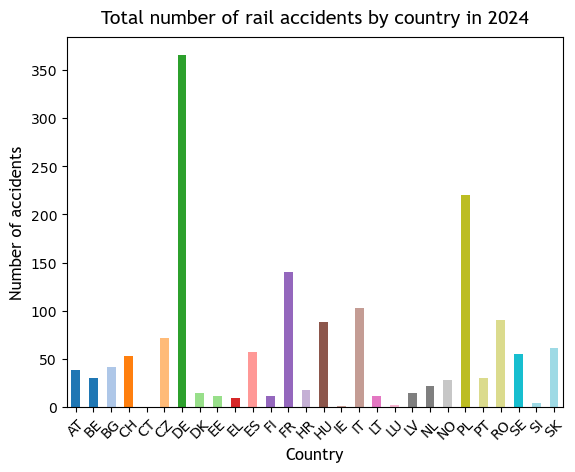

In [6]:
# extract accidents row
accidents = incidents2024[incidents2024["CSI"] == "Total number of significant accidents"].drop(columns=["CSI"]).transpose()
accidents = accidents.rename(columns={0: "Total number of significant accidents"}, inplace=False)
accidents["Total number of significant accidents"] = accidents["Total number of significant accidents"].astype("int")
acc_series = accidents["Total number of significant accidents"]

colours = plt.cm.tab20(np.linspace(0, 1, len(acc_series)))
acc_series.plot.bar(color=colours)

# plot chart
plt.title("Total number of rail accidents by country in 2024", fontname="Trebuchet MS", fontsize=14, pad=10)
plt.xlabel("Country", fontsize=12, fontname="Trebuchet MS")
plt.ylabel("Number of accidents", fontsize=12, fontname="Trebuchet MS")
plt.xticks(rotation=45)
plt.show()

Here we can see that Germany has vastly more train accidents than any other country at 366. Poland, France and Italy also have high numbers of incidents at 220, 140, 103 respectively. Now let's see what types of incident make up Germany's accidents.

C:\Users\amyed\AppData\Local\Temp\ipykernel_71136\318908800.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  germany_atype_isolated.drop([0], inplace=True)


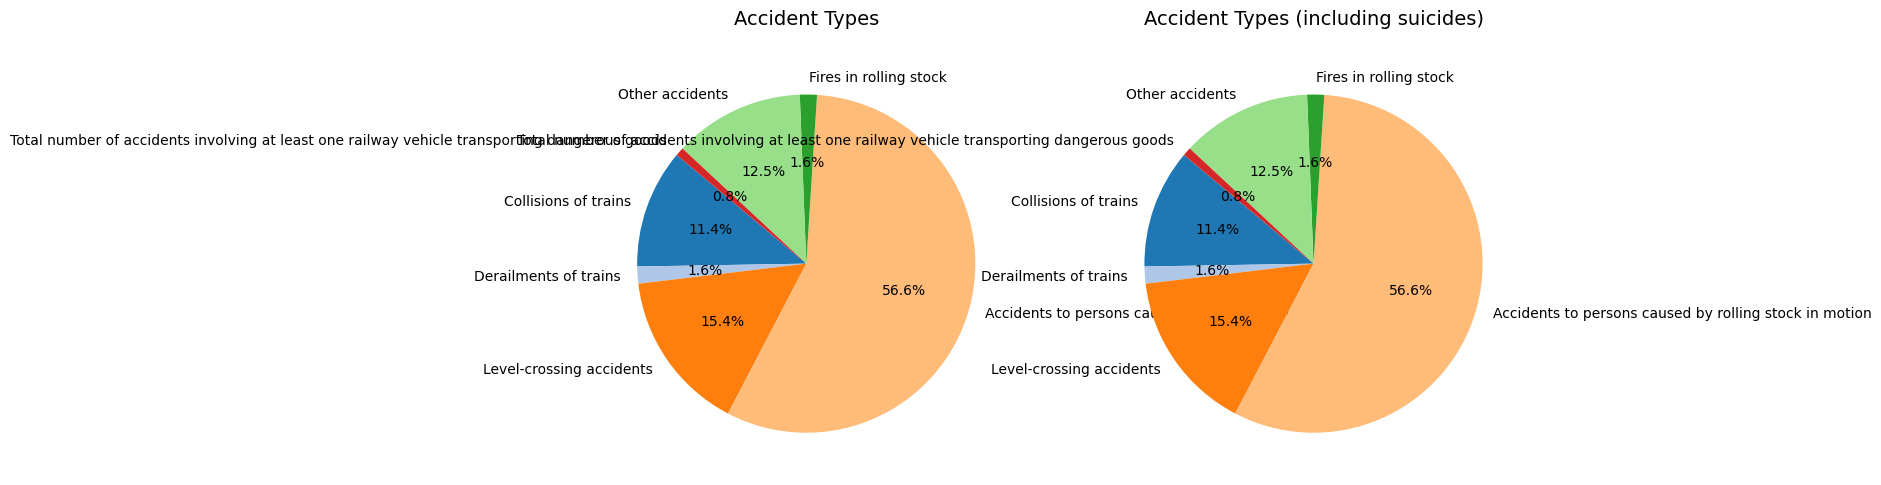

In [8]:
# formatting
germany_atype_isolated = incidents2024[["CSI", "DE"]]
germany_atype_isolated.drop([0], inplace=True)
germany_atype_isolated = germany_atype_isolated.reset_index()
germany_atype_isolated = germany_atype_isolated.iloc[:, 1:]

# isolating the distinct accient types in the dataset
unique_rows = ["Collisions of trains", #N01
                   "Derailments of trains", #N02
                   "Level-crossing accidents", #N03
                   "Accidents to persons caused by rolling stock in motion", #N04
                   "Fires in rolling stock", #N05
                   #"Suicides", #N07
                   #"Attempted suicides", #N08
                   "Total number of accidents involving at least one railway vehicle transporting dangerous goods", #N18
                   "Other accidents"] #N06

unique_rows_w_suicides = unique_rows + ["Suicides", "Attempted suicides"]

germany_atype_isolated = germany_atype_isolated[germany_atype_isolated["CSI"].isin(unique_rows)]
germany_atype_suicides = germany_atype_isolated[germany_atype_isolated["CSI"].isin(unique_rows_w_suicides)]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 6))
#germany_atype_isolated.plot(kind="pie", y="DE", labels=germany_atype_isolated["CSI"], autopct="%1.1f%%", figsize=(6, 6))
#plt.ylabel("")

# plot chart 1
ax1.pie(germany_atype_isolated["DE"], labels=germany_atype_isolated["CSI"], autopct="%1.1f%%", startangle=140, colors=plt.cm.tab20.colors)
ax1.set_title("Accident Types", fontsize=14, pad=20)

# plot chart 2
ax2.pie(germany_atype_suicides["DE"], labels=germany_atype_suicides["CSI"], autopct="%1.1f%%", startangle=140, colors=plt.cm.tab20.colors)
ax2.set_title("Accident Types (including suicides)", fontsize=14, pad=20)

plt.show()

Here we can see that suicides and attempted suicides make up the lion's share of rail accidents, with 688 casualties in Germany in 2024 alone. After this, accidents are most often caused by people being hurt by vehicles in motion.